## Lab 8. The Bianconi-Barabási Model

### Task 1: Implement the Bianconi-Barabási Model

In [1]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import random

In [2]:
def bianconi_barabasi_graph(N, m, eta_distribution):
    # Initialization
    m0 = m
    G = nx.complete_graph(m0)
    for i in range(m0):
        G.nodes[i]["fitness"] = eta_distribution()

    # Growth
    for j in range(m0, N):
        existing_nodes = np.arange(j) # Exclude the new node
        total_sum = sum(G.nodes[i]["fitness"] * G.degree(i) for i in range(j))
        G.add_node(j)
        G.nodes[j]["fitness"] = eta_distribution()

        # Preferential attachment based on fitness and degree
        prob = np.zeros(j)

        # Calculate attachment probabilities
        for i in range(j):
            prob[i] = G.nodes[i]["fitness"] * G.degree(i) / total_sum

        # Select m nodes to connect to
        targets = np.random.choice(existing_nodes, size=m, replace=False, p=prob)
        for t in targets:
            G.add_edge(j, t)

    return G
        

In [24]:
def bianconi_barabasi_graph(N, m, eta_distribution):
    m0 = m
    G = nx.complete_graph(m0)

    for i in range(m0):
        G.nodes[i]["fitness"] = eta_distribution()

    for j in range(m0, N):
        existing_nodes = np.arange(j)

        total_sum = sum(G.nodes[i]["fitness"] * G.degree(i) for i in range(j))

        G.add_node(j)
        G.nodes[j]["fitness"] = eta_distribution()

        # Case 1: total_sum = 0 → no degrees yet, choose uniformly
        if total_sum == 0:
            targets = np.random.choice(existing_nodes, size=m, replace=False)
        else:
            # Preferential attachment based on degree × fitness
            prob = np.array([
                G.nodes[i]["fitness"] * G.degree(i) / total_sum for i in range(j)
            ])

            targets = np.random.choice(existing_nodes, size=m, replace=False, p=prob)

        for t in targets:
            G.add_edge(j, t)

    return G


In [3]:
eta_distribution = np.random.uniform
N = 10000
m = 2
G = bianconi_barabasi_graph(N, m, eta_distribution)

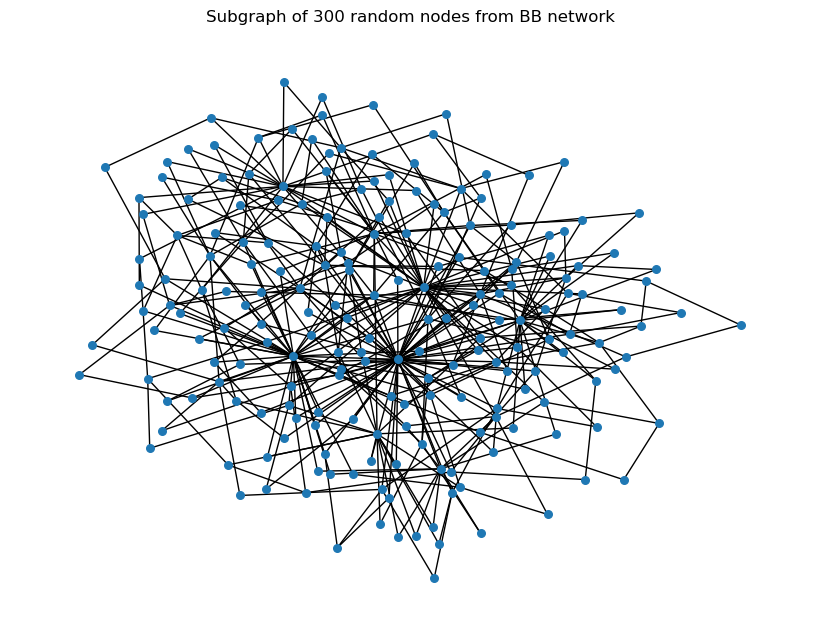

In [4]:
# Pick a random sample of nodes

H = G.subgraph(np.arange(200))  # subgraph view

plt.figure(figsize=(8,6))
nx.draw(H, node_size=30, with_labels=False)
plt.title("Subgraph of 300 random nodes from BB network")
plt.show()

### Task 2: Measure and Visualize the Degree Distribution

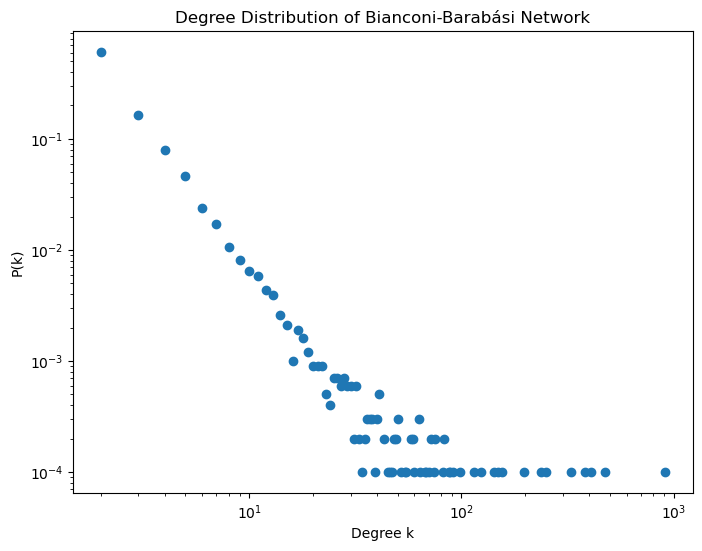

In [5]:
# Aggregate degree distribution
degrees = [G.degree(n) for n in G.nodes()]
unique_deg, counts = np.unique(degrees, return_counts=True)

# Normalize to get probability P(k)
prob = counts / counts.sum()

# Plot degree distribution
plt.figure(figsize=(8, 6))
plt.plot(unique_deg, prob, marker='o', linestyle='None')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Degree k')
plt.ylabel('P(k)')
plt.title('Degree Distribution of Bianconi-Barabási Network')
plt.show()



In [6]:
ba_graph = nx.barabasi_albert_graph(N, m)

# Aggregate degree distribution
ba_degrees = [ba_graph.degree(n) for n in ba_graph.nodes()]
ba_unique_deg, ba_counts = np.unique(ba_degrees, return_counts=True)

# Normalize to get probability P(k)
ba_prob = ba_counts / ba_counts.sum()


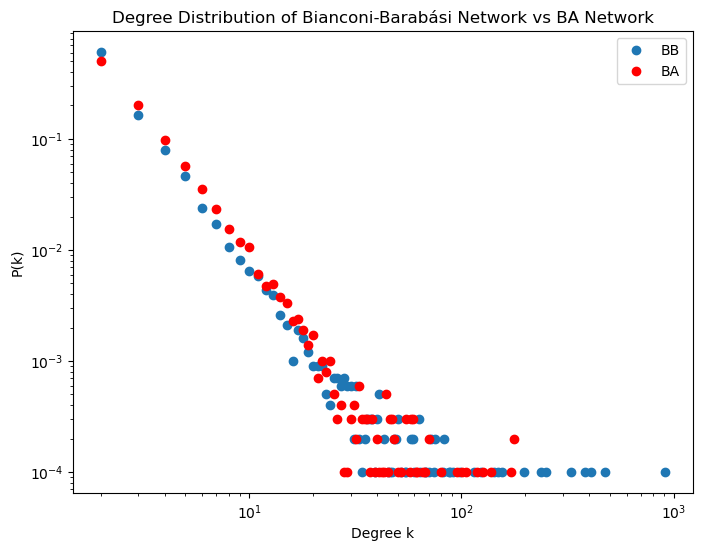

In [7]:
# Plot degree distribution
plt.figure(figsize=(8, 6))
# BB model
plt.plot(unique_deg, prob, marker='o', linestyle='None', label="BB")
# BA model
plt.plot(ba_unique_deg, ba_prob, marker='o', linestyle='None',color="red", label="BA")

plt.legend()
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Degree k')
plt.ylabel('P(k)')
plt.title('Degree Distribution of Bianconi-Barabási Network vs BA Network')
plt.show()

**Question: What is the primary visual difference? The B² model often has a
"flatter" tail, indicating a higher probability of very high-degree nodes (hubs)
due to the fitness effect.**

The main difference is that the BB model has a flatter tail, meaning that it has more nodes with a higher degree, which means that there is a higher probability of very high degree hubs because of the fitness effect.

### Task 3: Fitness-Dependent Degree Distribution - The Key Measurement

In [8]:
N = 5000
G = bianconi_barabasi_graph(N, m, eta_distribution)

# Add the time of addition property
for i in range(m):
    G.nodes[i]["time_of_addition"] = 0

for i in range(m, N):
    G.nodes[i]["time_of_addition"] = i - m + 1

In [9]:
degrees = [G.degree[n] for n in G.nodes()]


In [10]:
ages = [G.nodes[n]["time_of_addition"] for n in G.nodes()]

In [15]:
etas = np.array([G.nodes[n]["fitness"] for n in G.nodes()])

<Figure size 800x600 with 0 Axes>

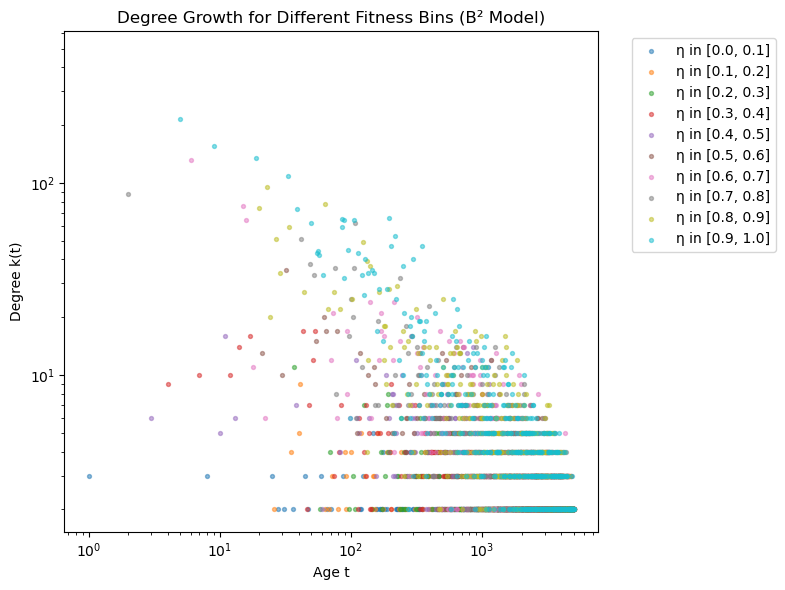

In [20]:
degrees = np.array([G.degree[n] for n in G.nodes()])
ages    = np.array([G.nodes[n]["time_of_addition"] for n in G.nodes()])
etas    = np.array([G.nodes[n]["fitness"] for n in G.nodes()])

num_bins = 10
bin_edges = np.linspace(0, 1, num_bins + 1)
bin_indices = np.digitize(etas, bin_edges) - 1   # numpy array
bin_indices = np.array(bin_indices)               # ensure numpy


plt.figure(figsize=(8, 6))

plt.figure(figsize=(8, 6))

# Scatter plot for each fitness bin
for b in range(num_bins):
    mask = (bin_indices == b)
    mask = np.array(mask)       

    if mask.sum() == 0:
        continue
    
    deg_b = degrees[mask]
    age_b = ages[mask]

    plt.scatter(age_b, deg_b, s=8, alpha=0.5,
                label=f"η in [{bin_edges[b]:.1f}, {bin_edges[b+1]:.1f}]")

# Log–log axes and labels
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Age t")
plt.ylabel("Degree k(t)")
plt.title("Degree Growth for Different Fitness Bins (B² Model)")

# Legend outside the plot
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()


## Task 4: Demonstrating the Bose-Einstein Condensation

In [21]:
def power_law_fitness(alpha=2, xmin=0.01):
    """
    Draws fitness from η = 1 - x, where x ~ power-law P(x) ~ x^{-alpha}.
    """
    u = np.random.rand()
    x = xmin * (1 - u)**(-1 / (alpha - 1))   # inverse transform sampling
    x = min(x, 1.0)  # cap at 1
    return 1 - x

def eta_distribution():
    return power_law_fitness(alpha=2, xmin=0.01)


In [25]:
N = 2000
m = 1

G = bianconi_barabasi_graph(N, m, eta_distribution)


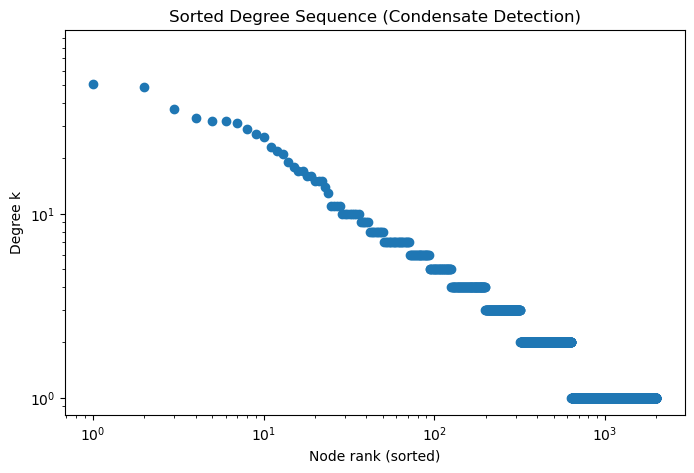

In [26]:
# Degree of each node from highest to lowest
# Compute degrees
degrees = np.array([G.degree(n) for n in G.nodes()])

# Sort in descending order
degrees_sorted = np.sort(degrees)[::-1]

plt.figure(figsize=(8, 5))
plt.plot(degrees_sorted, marker="o", linestyle="None")
plt.xlabel("Node rank (sorted)")
plt.ylabel("Degree k")
plt.title("Sorted Degree Sequence (Condensate Detection)")
plt.yscale("log")
plt.xscale("log")
plt.show()


In [27]:
# Total number of edges
L = G.number_of_edges()

# Degrees
degrees = np.array([G.degree(n) for n in G.nodes()])

# Top 3 degrees
top3 = np.sort(degrees)[-3:][::-1]   # largest first

# Fraction of total degree = top3 / (2L)
fraction_top3 = top3.sum() / (2 * L)

print("Top 3 node degrees:", top3)
print(f"Total edges: {L}")
print(f"Fraction of all links held by top 3 nodes: {fraction_top3:.4f}")


Top 3 node degrees: [80 51 49]
Total edges: 1999
Fraction of all links held by top 3 nodes: 0.0450


In [28]:
ratio = degrees_sorted[0] / degrees_sorted[1]
print("k1 / k2 ratio =", ratio)


k1 / k2 ratio = 1.5686274509803921


We implemented the Bianconi–Barabási model with a broad (power-law-like) fitness distribution. We then measured condensation by sorting node degrees and computing the fraction of links held by the highest-degree nodes.

For 

N=2000 and 

m=1, the ratio of the largest to second-largest degree is 

k
1
	​

/k
2
	​

≈1.57, and the top node holds only 

f
1
	​

 of all links. This indicates that, for our parameter choice, the system is not in a strongly condensed phase; there is no single “winner-takes-all” hub.

This suggests either that the finite system size is too small to observe condensation, or that our fitness distribution is not broad enough / not sufficiently weighted near the maximal fitness to trigger a condensate.